#1. Importar todas las librerías necesarias (+0.15 puntos)



In [71]:
import random

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#2. Inicializar algunas variables que despues modificaremos. (+0.15 puntos)

In [72]:
df = None
hostnames = []


dictionary_os = {'L': 'Linux', 'S' : 'Solaris', 'A' : 'AIX', 'H': 'HP-UX'} # aquí definí los diccionarios que use para la creación de la tabla, en lugar de usar ifs en la función más abajo.

dictionary_environment = {'D' : 'Development', 'I' : 'Integration', 'T' : 'Testing', 'S' : 'Staging', 'P': 'Production'}

dictionary_country = {'NOR' : 'Norway', 'FRA' : 'France', 'ITA' : 'Italy', 'ESP' : 'Spain', 'DEU' : 'Germany','IRL' : 'Ireland'}


sistema_operativo = ['L', 'S', 'A', 'H'] # definí estas listas para usar los parametros de la función random.choices. Se necesita una lista con los elementos y otra con la proporción o peso que queremos para la selección.
porcentaje_sistema_operativo = [4, 3, 2, 1]

entorno = ['D', 'I', 'T', 'S', 'P']
porcentaje_entorno = [10, 10, 25, 25, 30]

paises = ['NOR', 'FRA', 'ITA', 'ESP', 'DEU','IRL']
porcentaje_paises = [6, 9, 16, 16, 23, 30]

#3. Crear una función para generar las mascotas en base a unas reglas (+1.5 puntos)

In [73]:
def set_hostnames(number_of_hosts):

    lista_sistema_operativo = random.choices(sistema_operativo, k = number_of_hosts, weights = porcentaje_sistema_operativo) # aquí decidí usar los parametros del metodo random.choices para hacer las listas.
    lista_entorno = random.choices(entorno, k = number_of_hosts, weights = porcentaje_entorno)
    lista_paises = random.choices(paises, k=number_of_hosts, weights=porcentaje_paises)

    for i in range(number_of_hosts):
        nodo=1
        hostname_verificar= lista_sistema_operativo[i] + lista_entorno[i] + lista_paises[i] + str(f'{nodo:03}')
        while hostname_verificar in hostnames:
            nodo+=1
            hostname_verificar = lista_sistema_operativo[i] + lista_entorno[i] + lista_paises[i] + str(f'{nodo:03}')
        hostnames.append(hostname_verificar)


#4. Crear una función para obtener el Os. (+0.5 puntos)

In [74]:
def get_os(hostname):
    if hostname[0] in dictionary_os:
        os = dictionary_os[hostname[0]]
    else:
        os = 'Unknow'
    return os


#5. Crear una función para obtener el environment. (+0.5 puntos)

In [75]:
def get_environment(hostname):
    if hostname[1] in dictionary_environment:
        environment = dictionary_environment[hostname[1]]
    else:
        environment = 'Unknow'
    return environment

#6. Crear una función para obtener el country (+0.5 puntos)

In [76]:
def get_country(hostname):
    if hostname[2:5] in dictionary_country:
        country = dictionary_country[hostname[2:5]]
    else:
        country = 'Unknown'
    return country

#6.1 Crear una función para obtener el nodo.

In [77]:
def get_node(hostname):
    node= int(hostname[-3:])
    return node

#7. Crear una función para generar el DataFrame. (+1 punto)

In [78]:
def set_dataframe(count):
 global df
 dataset = [] # definí aqui dataset para que cada vez que se ejecutara la función, se creara un dataset nuevo. Si no cada vez que se ejecutaba la función se añadia al dataset anteriormente generado.
 set_hostnames(count)

 for name in hostnames:
     dataset.append({
         'hostname' : name ,
         'os' : get_os(name),
         'environment' : get_environment(name),
         'country' : get_country(name),
         'node' : get_node(name)
      })

 df = pd.DataFrame(dataset)

# 8. Crear el DataFrame. (+0.2 puntos)

In [79]:
set_dataframe(1500)
df

,hostname,os,environment,country,node
0,LPITA001,Linux,Production,Italy,1
1,ADDEU001,AIX,Development,Germany,1
2,SPITA001,Solaris,Production,Italy,1
3,LPDEU001,Linux,Production,Germany,1
4,LSIRL001,Linux,Staging,Ireland,1
...,...,...,...,...,...
1495,ATFRA011,AIX,Testing,France,11
1496,APDEU021,AIX,Production,Germany,21
1497,LSIRL049,Linux,Staging,Ireland,49
1498,LPDEU051,Linux,Production,Germany,51


#9. Guardar el DataFrame generado en un fichero CSV. (0.5 puntos)


In [80]:
df.to_csv(
r'hosts.csv',
encoding='ISO-8859-1',
header=True,
index=False
)

df_hosts = pd.read_csv(
r'hosts.csv',
encoding='ISO-8859-1',
delimiter=','
)

df_hosts

,hostname,os,environment,country,node
0,LPITA001,Linux,Production,Italy,1
1,ADDEU001,AIX,Development,Germany,1
2,SPITA001,Solaris,Production,Italy,1
3,LPDEU001,Linux,Production,Germany,1
4,LSIRL001,Linux,Staging,Ireland,1
...,...,...,...,...,...
1495,ATFRA011,AIX,Testing,France,11
1496,APDEU021,AIX,Production,Germany,21
1497,LSIRL049,Linux,Staging,Ireland,49
1498,LPDEU051,Linux,Production,Germany,51


#10. Generar un único gráfico, agrupando para cada país (country) los entornos (environment). (+0.5 puntos)

<Axes: xlabel='country'>

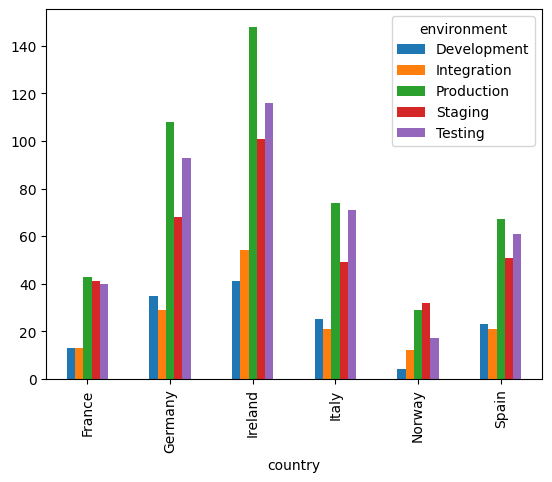

In [81]:
df.groupby(['country', 'environment']).size().unstack().plot(kind='bar')

#11. Crear una figura con 4 gráficos en una malla de 2 filas y 2 columnas. (+4.5 puntos)

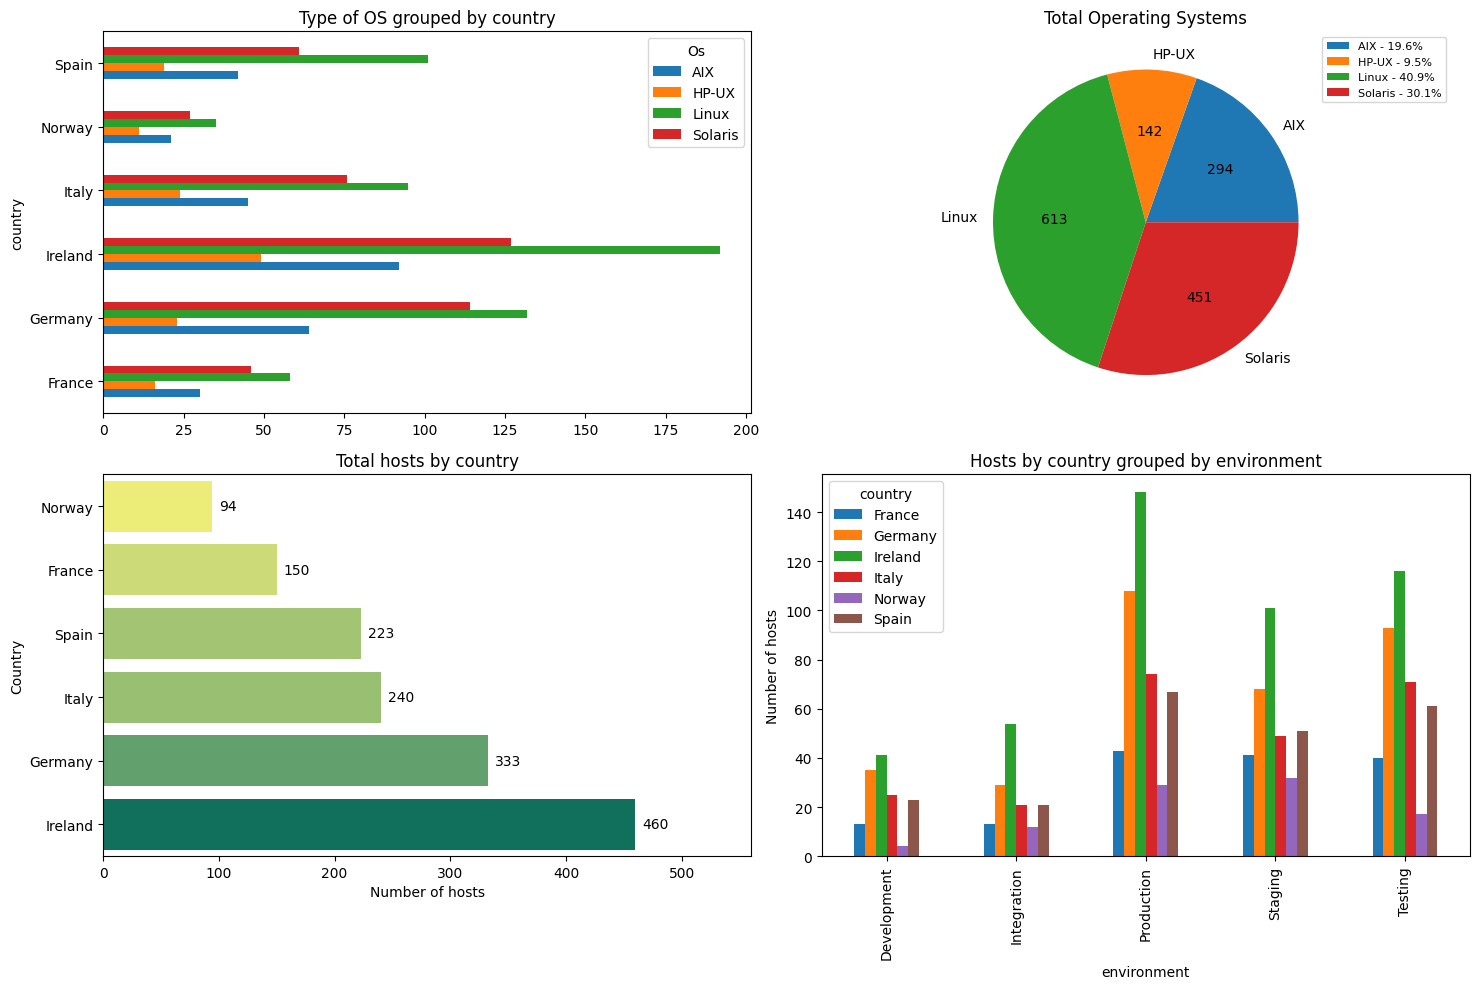

In [82]:
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

df.groupby(['country', 'os']).size().unstack().plot(kind='barh', ax=axs[0, 0]).legend(fontsize=10, title='Os')
axs[0, 0].set_title('Type of OS grouped by country')

df.groupby([ 'os']).size().plot(kind='pie',
                                autopct=lambda pct: int(round(pct * (len(df)) / 100)), # esta linea es para que aparezca el número de sistemas operativos de cada tipo. --No encontre una manera mas directa que usar el porcentaje y hacer como "ingenieria inversa" para conseguir el número original.
                                ax=axs[0, 1]) # Deje la tabla así porque creo que es un poco más facil de leer, pero si se quiere que aparezca justo como la imagen que aparece en la tarea se tendría que agregar esto al final: "labels=None, pctdistance=1.1"
axs[0, 1].set_title('Total Operating Systems')
axs[0, 1].legend(labels=[f"{name} - {100 * val / len(df):.1f}%" for name, val in df.groupby(['os']).size().items()],
                 loc='upper right',
                 bbox_to_anchor=(1.3, 1),
                 fontsize=8)


sns.barplot(data=df['country'].value_counts().sort_values().reset_index(),
            y='country',
            x='count',
            hue='count',
            palette='summer_r',
            ax=axs[1, 0],
            legend=False)

axs[1, 0].set_title('Total hosts by country')
axs[1, 0].set_xlabel('Number of hosts')
axs[1, 0].set_ylabel('Country')
for container in axs[1, 0].containers:
    axs[1, 0].bar_label(container, padding=5)
axs[1, 0].set_xlim(0, df['country'].value_counts().max() + 100)

df.groupby(['environment', 'country']).size().unstack().plot(kind='bar', ylabel='Number of hosts', ax=axs[1,1])
axs[1, 1].set_title('Hosts by country grouped by environment')

fig.tight_layout()